<a href="https://colab.research.google.com/github/manuelrecayte/proyectos-personales/blob/main/manuelrecayte/PCD/Proyecto/ProyectofinalPCD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
import statsmodels.stats.api as sms

In [2]:
url_repositorio = "https://raw.githubusercontent.com/manuelrecayte/proyectos-personales/refs/heads/main/proyecto-pcd/data/datoscangrejo.csv"

data = pd.read_csv(url_repositorio)
#print(data.shape)

data = data[data["Sex"] != "I"]
print(data.shape)

data.columns = [col.replace(' ', '_').replace('.', '_') for col in data.columns]
resumen_num = data.describe()
print(resumen_num)

(2660, 9)
            Length     Diameter       Height       Weight  Shucked_Weight  \
count  2660.000000  2660.000000  2660.000000  2660.000000     2660.000000   
mean      1.423943     1.116198     0.386114    28.817475       12.421792   
std       0.239300     0.196878     0.094031    12.821337        5.989869   
min       0.387500     0.275000     0.037500     0.439417        0.184272   
25%       1.287500     1.000000     0.337500    19.855281        8.093782   
50%       1.462500     1.150000     0.387500    28.462898       12.232809   
75%       1.587500     1.250000     0.437500    36.560224       16.063535   
max       2.037500     1.625000     2.825000    80.101512       42.184056   

       Viscera_Weight  Shell_Weight          Age  
count     2660.000000   2660.000000  2660.000000  
mean         6.307034      8.260565    10.915038  
std          2.880555      3.642927     3.058831  
min          0.085048      0.141747     3.000000  
25%          4.323299      5.808104     9

En el trabajo anterior, vimos que los cangrejos con sexo indeterminado son cangrejo, a los que debido a su corta edad no se les puede asignar un sexo. Para este nuevo analisis, ya no nos interesa modelar bien los cangrejos jovenes, asi que estos datos son removidos.

A su vez se hace un cambio en el nombre de las variables ya que los espacios dan problemas en algunas partes del analisis.

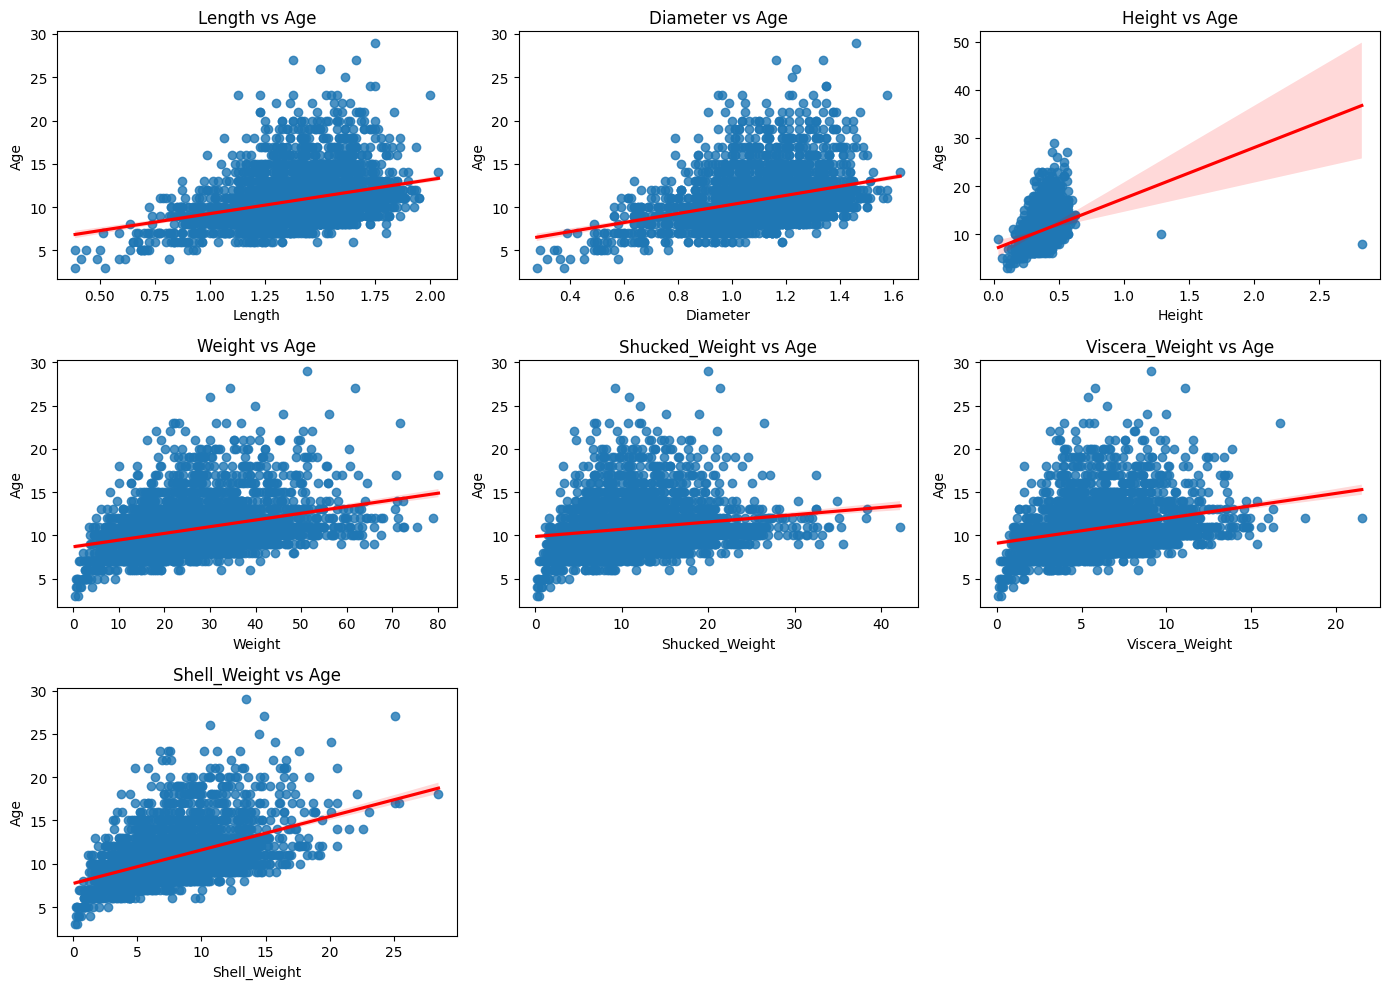

In [3]:
#Graficos de las variables contra edad
cols = ['Length', 'Diameter', 'Height', 'Weight', 'Shucked_Weight', 'Viscera_Weight', 'Shell_Weight']
plt.figure(figsize=(14, 10))
for i, col in enumerate(cols):
    plt.subplot(3, 3, i + 1)
    sns.regplot(x=col, y='Age', data=data, line_kws={'color': 'red'})
    plt.title(f"{col} vs Age")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Boxplot de Age vs Sex')

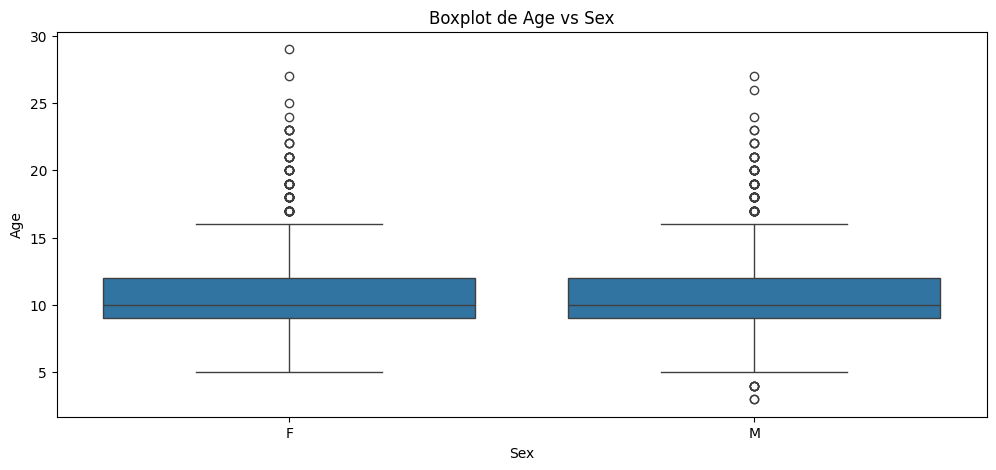

In [4]:
plt.figure(figsize=(12, 5))
sns.boxplot(x='Sex', y='Age', data=data)
plt.title("Boxplot de Age vs Sex")

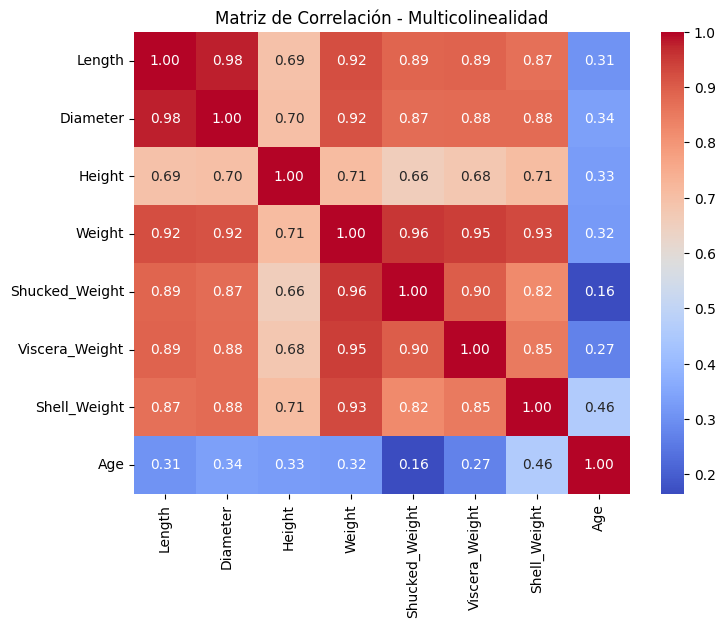

In [6]:
#Visualizacion de la matriz de correlaciones
corr = data.select_dtypes(include=[np.number]).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de Correlación - Multicolinealidad")
plt.show()

Claramente hay dos datos atipicos de Height, probablemente provocados por un error en la medición, para no alterar los resultados por solo dos datos, se decidió removerlos. Tambien es apreciable la alta correlación entre muchas de las variables.

In [7]:
#se detectan y eliminan los dos datos extremadamente atipicos de height
data_sin_outliers = data.sort_values(by='Height').iloc[:-2].reset_index(drop=True)

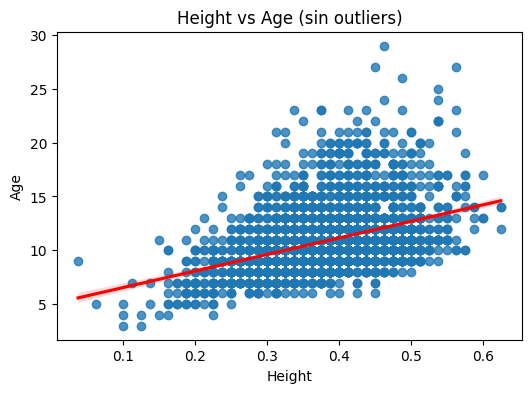

In [8]:
plt.figure(figsize=(6, 4))
sns.regplot(x='Height', y='Age', data=data_sin_outliers, line_kws={'color': 'red'})
plt.title("Height vs Age (sin outliers)")
plt.show()

Lo que buscamos es tomar solamente los datos de los cangrejos que dejaron de crecer fisicamente de manera abrupta. Para ello implementamos *Random Forest* buscando determinar que variable mejor explica el cambio en la edad, para asi, junto con su grafico determinar un umbral arbitrario, que permita discriminar del total de los datos unicamente aquellos que buscamos.

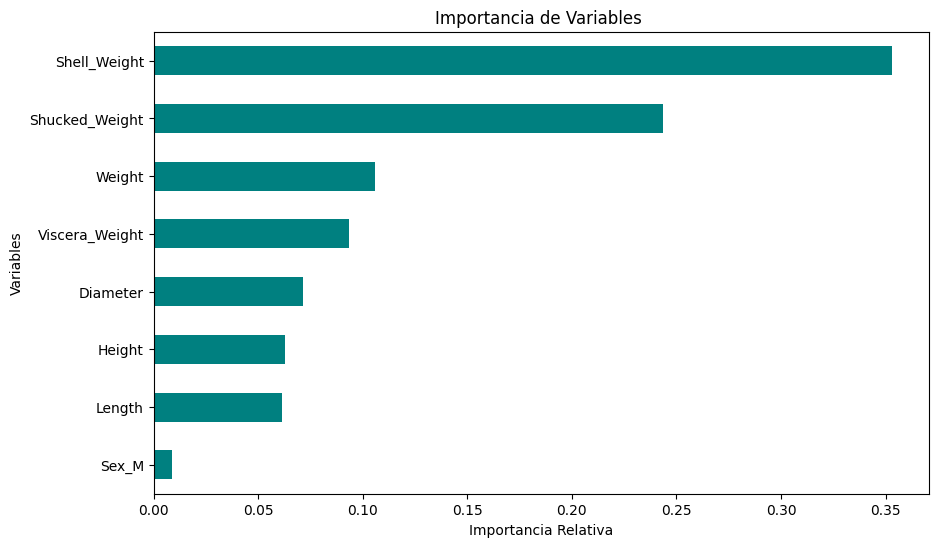

Importancia de Variables (Random Forest)
Shell_Weight      0.352982
Shucked_Weight    0.243506
Weight            0.105872
Viscera_Weight    0.093327
Diameter          0.071392
Height            0.062626
Length            0.061378
Sex_M             0.008917
dtype: float64


In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_predict

X = data_sin_outliers.drop(columns=['Age'])
y = data_sin_outliers['Age']

#convertimos la var sex a dummy
X = pd.get_dummies(X, drop_first=True)
cols = X.columns.tolist()

#se entrena el random forest
rf = RandomForestRegressor(n_estimators=500, random_state=42, min_samples_split=5)
rf.fit(X, y)

#vemos las importancias de cada variable
imp = pd.Series(rf.feature_importances_, index=cols).sort_values(ascending=False)

#visualizacion
plt.figure(figsize=(10, 6))
imp.plot(kind='barh', color='teal')
plt.title("Importancia de Variables ")
plt.xlabel("Importancia Relativa")
plt.ylabel("Variables")
plt.gca().invert_yaxis()
plt.show()

print("Importancia de Variables (Random Forest)")
print(imp)

A partir de los resultados del *Random Forest* obtuvimos que la variable de mayor importancia es *Shell_Weight* (Peso de Caparazón).

Viendo el grafico Shell_Weight vs Age se dedujo que rondando las 5 onzas. (aprox. 140g)

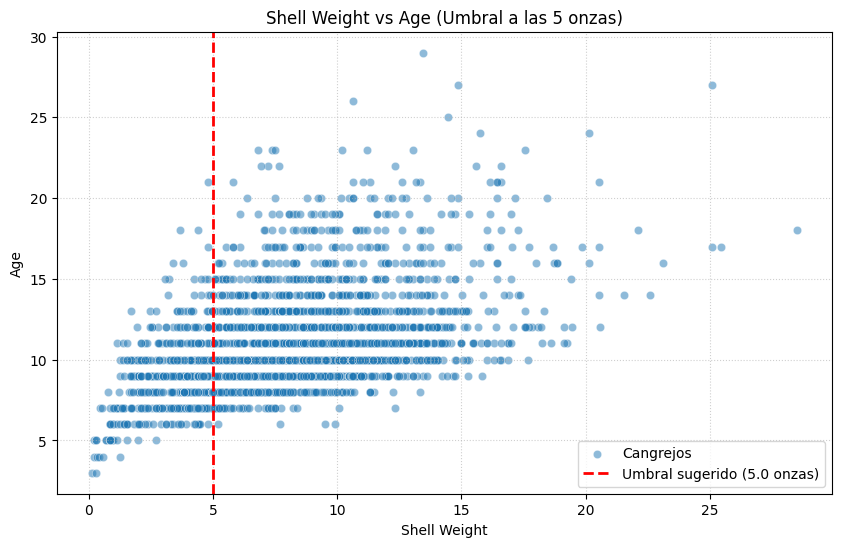

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data_sin_outliers,
    x='Shell_Weight',
    y='Age',
    alpha=.5,
    label='Cangrejos'
)

plt.axvline(
    x=5.0,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Umbral sugerido (5.0 onzas)'
)

plt.title("Shell Weight vs Age (Umbral a las 5 onzas)")
plt.xlabel("Shell Weight")
plt.ylabel("Age")
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

Tomando ese umbral particionamos los datos, y ajustamos un modelo para los datos seleccionados.

In [11]:
# Filtrar los datos sin outliers para quedarnos únicamente con Shell_Weight >= 5
df = data_sin_outliers[data_sin_outliers['Shell_Weight'] >= 5.0].reset_index(drop=True)

print("Dimensiones antes del filtro:", data_sin_outliers.shape)
print("Nuevas dimensiones:", df.shape)

Dimensiones antes del filtro: (2658, 9)
Nuevas dimensiones: (2158, 9)


Se hace un proceso de Seleccion de variables de distintas formas

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LassoCV

X_dummies = pd.get_dummies(data.drop(columns=['Age']), drop_first=True)
X = X_dummies.values
y = data['Age'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#se busca el alpha optimo para lasso
lasso_cv = LassoCV(alphas=None, cv=5, random_state=42)
lasso_cv.fit(X_scaled, y)

print("Mejor alpha:", lasso_cv.alpha_)

# ajustamos lasso con alpha optimo
lassomod_cv = Lasso(alpha=lasso_cv.alpha_, random_state=42)
lassomod_cv.fit(X_scaled, y)

# se extraen los coef para lasso
coef_lasso_cv = pd.Series(lassomod_cv.coef_, index=X_dummies.columns)
print("Coef de Lasso (con alpha optimo):")
print(coef_lasso_cv)

# ajustamos lasso con alpha 0.08 (arbitrario)
lassomod = Lasso(alpha=0.08, random_state=42)
lassomod.fit(X_scaled, y)

# se extraen los coef para este lasso
coef_lasso = pd.Series(lassomod.coef_, index=X_dummies.columns)
print("Coef de Lasso (con alpha = 0.08):")
print(coef_lasso)

Mejor alpha: 0.0030304649657254784
Coef de Lasso (con alpha optimo):
Length           -0.325600
Diameter          0.728217
Height            0.246622
Weight            4.077578
Shucked_Weight   -4.101298
Viscera_Weight   -0.875812
Shell_Weight      1.201155
Sex_M             0.000000
dtype: float64
Coef de Lasso (con alpha = 0.08):
Length            0.000000
Diameter          0.088575
Height            0.184630
Weight            0.000000
Shucked_Weight   -1.659464
Viscera_Weight    0.000000
Shell_Weight      2.483735
Sex_M            -0.000000
dtype: float64


Evaluamos los distintos modelos ajustados

In [ ]:
# Modelo segun Lasso (alpha = 0.08)
sex_det_col = [c for c in X_dummies.columns if 'Sex_det' in c]
vars_lasso = ['Diameter', 'Height', 'Shucked_Weight', 'Shell_Weight'] + sex_det_col

formula_lasso = 'Age ~ ' + ' + '.join(vars_lasso)
df_lasso = pd.concat([data[['Age']], X_dummies[vars_lasso]], axis=1)
modelo_lasso = smf.ols(formula_lasso, data=df_lasso).fit()

# Modelo segun Lasso (alpha optimo)
vars_lasso_cv = coef_lasso_cv[coef_lasso_cv != 0].index.tolist()
formula_lasso_cv = 'Age ~ ' + ' + '.join(vars_lasso_cv)
df_lasso_cv = pd.concat([data[['Age']], X_dummies[vars_lasso_cv]], axis=1)
modelo_lasso_cv = smf.ols(formula_lasso_cv, data=df_lasso_cv).fit()

print("Resumen Modelo según Lasso (alpha = 0.08)")
print(modelo_lasso.summary())

print("Resumen Modelo según Lasso (alpha optimo)")
print(modelo_lasso_cv.summary())

print("R cuadrados de cada Lasso: ", "lasso .08:",modelo_lasso.rsquared, ";   lasso opt:",modelo_lasso_cv.rsquared)


Resumen Modelo según Lasso (alpha = 0.08)
                            OLS Regression Results                            
Dep. Variable:                    Age   R-squared:                       0.364
Model:                            OLS   Adj. R-squared:                  0.363
Method:                 Least Squares   F-statistic:                     379.1
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          1.51e-258
Time:                        00:45:34   Log-Likelihood:                -6146.9
No. Observations:                2660   AIC:                         1.230e+04
Df Residuals:                    2655   BIC:                         1.233e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
In

Con validación cruzada, evaluamos los modelos de Lasso, examinando su poder predictivo para terminar decantandonos por uno.

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score

# Variables dummy
X_dummies = pd.get_dummies(data.drop(columns=['Age']))
X = X_dummies.values
y = data['Age'].values

# 10 kfolds para VC
kf = KFold(n_splits=10, shuffle=True, random_state=42)

r2s_opt = []
r2s_08 = []

# Guardamos valores reales y predicciones para el óptimo (para mantener compatibilidad con el gráfico siguiente)
y_real_vc = []
y_pred_vc = []

i = 1
for tr, te in kf.split(X):
    X_tr, X_te = X[tr], X[te]
    y_tr, y_te = y[tr], y[te]

    scaler = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)

    # 1. Modelo con Alpha Óptimo (0.003)
    m_opt = Lasso(alpha=0.003, random_state=42)
    m_opt.fit(X_tr_sc, y_tr)
    preds_opt = m_opt.predict(X_te_sc)
    r2s_opt.append(r2_score(y_te, preds_opt))

    # Guardamos valores para mantener consistencia con los gráficos posteriores
    y_real_vc.extend(y_te)
    y_pred_vc.extend(preds_opt)

    # 2. Modelo con Alpha = 0.08
    m_08 = Lasso(alpha=0.08, random_state=42)
    m_08.fit(X_tr_sc, y_tr)
    preds_08 = m_08.predict(X_te_sc)
    r2s_08.append(r2_score(y_te, preds_08))

    print(f"Fold {i} -> R2 óptimo (0.003): {r2s_opt[-1]:.4f} | R2 (0.08): {r2s_08[-1]:.4f}")
    i += 1

mean_r2_opt = np.mean(r2s_opt)
mean_r2_08 = np.mean(r2s_08)

print("\nResultados Finales")
print(f"R2 medio Modelo Óptimo (alpha=0.003): {mean_r2_opt:.4f}")
print(f"R2 medio Modelo Restringido (alpha=0.08): {mean_r2_08:.4f}")


Fold 1 -> R2 óptimo (0.003): 0.3166 | R2 (0.08): 0.3004
Fold 2 -> R2 óptimo (0.003): 0.4331 | R2 (0.08): 0.3670
Fold 3 -> R2 óptimo (0.003): 0.3295 | R2 (0.08): 0.3124
Fold 4 -> R2 óptimo (0.003): 0.3523 | R2 (0.08): 0.3492
Fold 5 -> R2 óptimo (0.003): 0.3479 | R2 (0.08): 0.3235
Fold 6 -> R2 óptimo (0.003): 0.4689 | R2 (0.08): 0.4166
Fold 7 -> R2 óptimo (0.003): 0.3252 | R2 (0.08): 0.2821
Fold 8 -> R2 óptimo (0.003): 0.3522 | R2 (0.08): 0.2964
Fold 9 -> R2 óptimo (0.003): 0.3891 | R2 (0.08): 0.3433
Fold 10 -> R2 óptimo (0.003): 0.4347 | R2 (0.08): 0.3853

Resultados Finales
R2 medio Modelo Óptimo (alpha=0.003): 0.3749
R2 medio Modelo Restringido (alpha=0.08): 0.3376


MSE 5.802594548704176


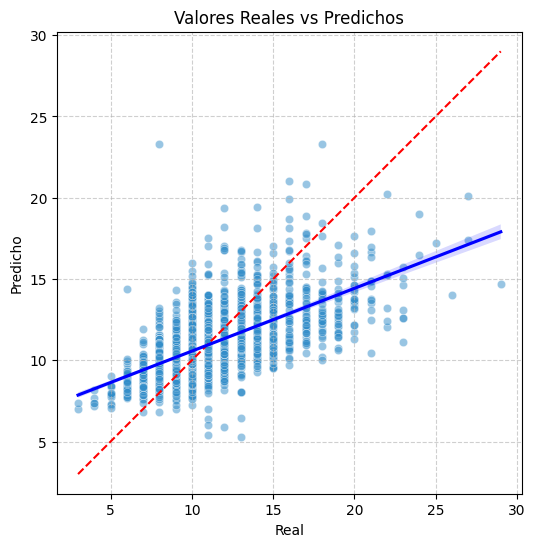

In [ ]:

predichos_vs_observados_vc = pd.DataFrame({'Real': y_real_vc, 'Predicho': y_pred_vc})

mse_vc = mean_squared_error(y_real_vc, y_pred_vc)
print("MSE", mse_vc)

plt.figure(figsize=(6, 6))
sns.scatterplot(data=predichos_vs_observados_vc, x='Real', y='Predicho', alpha=0.5, color='#328dc9')
plt.plot([min(y_real_vc), max(y_real_vc)], [min(y_real_vc), max(y_real_vc)], color='red', linestyle='--')
sns.regplot(data=predichos_vs_observados_vc, x='Real', y='Predicho', scatter=False, color='blue')
plt.title("Valores Reales vs Predichos")
plt.xlabel("Real")
plt.ylabel("Predicho")
plt.axis('equal')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

##Conclusiones

Luego de haber hecho la división de datos, y quedarnos solo con los considerados adultos, es apreciable como las variables disponibles en el dataset no son suficientes para poder predecir la edad de un cangrejo fuera de su etapa de crecimiento, sin importar si se quitan o no variables. En el ultimo grafico es apreciable como a los pocos cangrejos que se mantuvieron luego de la división, se los sobreestima en demasía, pero rapidamente cambia a una subestimación severa.